In [1]:
import geopandas as gpd
from shapely.geometry import box

# 1. Load and reproject if needed
gdf = gpd.read_file("data/gip_network_ogd.gpkg")
if gdf.crs.to_epsg() != 4326:
    gdf = gdf.to_crs(epsg=4326)

# 2. Define (and optionally buffer) the Klagenfurt bbox
klagenfurt_bbox = box(14.25, 46.58, 14.36, 46.67)
print("Using bbox:", klagenfurt_bbox.bounds)

# 3. Filter with intersects to keep full edges crossing the box
klagenfurt_network = gdf[gdf.geometry.intersects(klagenfurt_bbox)]
print(f"Extracted {len(klagenfurt_network)} segments for Klagenfurt")

# 4. Inspect and save
print(klagenfurt_network.columns)
klagenfurt_network.to_file("klagenfurt_network.gpkg", driver="GPKG")


/Users/danieldeutsch/opt/anaconda3/envs/fleetpy/lib/python3.10/site-packages/pyogrio/geopandas.py:265: UserWarning: More than one layer found in 'gip_network_ogd.gpkg': 'EDGE_OGD' (default), 'NODE_OGD', 'GIP_LINKNETZ_OGD', 'LINEARUSE_OGD', 'TURNUSE_OGD', 'version'. Specify layer parameter to avoid this warning.
  result = read_func(


Using bbox: (14.25, 46.58, 14.36, 46.67)
Extracted 8900 segments for Klagenfurt
Index(['ACTION_ID', 'BAUSTATUS', 'EXTID', 'EXTORG', 'SUBNETID', 'FOW', 'FRC',
       'ANGLESTART', 'ANGLEEND', 'SHAPELENGTH', 'SUSTAINER', 'REGCODE',
       'EDGECAT', 'VALIDFROM', 'MAINNAMETEXT', 'VALIDTO', 'DWIDTH', 'SDE_ID',
       'OBJECTID', 'NODEFROMID', 'NODETOID', 'OWNER_ID', 'TIMESTAMP',
       'DBCONNECTOR', 'FEATURENAME', 'geometry'],
      dtype='object')


# Klagenfurt Network & Zone Diagnostic

Let's verify the network, zones, demand, and vehicle setup to ensure everything is configured correctly for the FleetPy simulation.

In [1]:
import pandas as pd
import os

# Check network files
network_dir = "data/networks/klagenfurt/base"
nodes = pd.read_csv(f"{network_dir}/nodes.csv")
edges = pd.read_csv(f"{network_dir}/edges.csv")

print("="*60)
print("NETWORK STRUCTURE")
print("="*60)
print(f"Nodes: {len(nodes):,} (range: {nodes['node_index'].min()} to {nodes['node_index'].max()})")
print(f"Edges: {len(edges):,}")
print(f"\nNode columns: {nodes.columns.tolist()}")
print(f"Edge columns: {edges.columns.tolist()}")
print(f"\nSample nodes:\n{nodes.head()}")

# Check zone mapping
zone_file = "data/zones/klagenfurt/base/node_zone_info.csv"
zones = pd.read_csv(zone_file)
print("\n" + "="*60)
print("ZONE STRUCTURE")
print("="*60)
print(f"Total nodes with zone info: {len(zones):,}")
print(f"Unique zones: {zones['zone_id'].nunique()}")
print(f"Zone IDs: {sorted(zones['zone_id'].unique())}")
print(f"\nZone distribution:")
print(zones['zone_id'].value_counts().sort_index())

# Check demand
demand_file = "data/demand/klagenfurt/matched/klagenfurt/demand_requests.csv"
demand = pd.read_csv(demand_file)
print("\n" + "="*60)
print("DEMAND STRUCTURE")
print("="*60)
print(f"Total requests: {len(demand):,}")
print(f"Columns: {demand.columns.tolist()}")
print(f"\nStart nodes: {demand['start'].min()} to {demand['start'].max()}")
print(f"End nodes: {demand['end'].min()} to {demand['end'].max()}")
print(f"Time range: {demand['rq_time'].min():.0f}s ({demand['rq_time'].min()/3600:.1f}h) to {demand['rq_time'].max():.0f}s ({demand['rq_time'].max()/3600:.1f}h)")
print(f"\nSample demand:\n{demand.head()}")

# Check if demand nodes exist in network
invalid_starts = demand[~demand['start'].isin(nodes['node_index'])]
invalid_ends = demand[~demand['end'].isin(nodes['node_index'])]
print(f"\n❌ Invalid start nodes: {len(invalid_starts)}")
print(f"❌ Invalid end nodes: {len(invalid_ends)}")

# Check vehicle initialization
vehicle_file = "data/vehicles/1.csv"
vehicles = pd.read_csv(vehicle_file, header=None, names=['vehicle_id', 'start_node'])
print("\n" + "="*60)
print("VEHICLE INITIALIZATION")
print("="*60)
print(f"Total vehicles in file: {len(vehicles)}")
print(f"Start nodes range: {vehicles['start_node'].min()} to {vehicles['start_node'].max()}")
invalid_veh_nodes = vehicles[~vehicles['start_node'].isin(nodes['node_index'])]
print(f"❌ Invalid vehicle start nodes: {len(invalid_veh_nodes)}")
if len(invalid_veh_nodes) > 0:
    print(f"   Examples: {invalid_veh_nodes.head()['start_node'].tolist()}")

NETWORK STRUCTURE
Nodes: 2,099 (range: 0 to 2098)
Edges: 5,658

Node columns: ['node_index', 'is_stop_only', 'pos_x', 'pos_y']
Edge columns: ['from_node', 'to_node', 'distance', 'travel_time', 'source_edge_id']

Sample nodes:
   node_index  is_stop_only      pos_x      pos_y
0           0             0  14.283312  46.621887
1           1             0  14.282699  46.622053
2           2             0  14.282816  46.621962
3           3             0  14.283340  46.621954
4           4             0  14.285916  46.621237

ZONE STRUCTURE
Total nodes with zone info: 2,099
Unique zones: 1
Zone IDs: [np.int64(1)]

Zone distribution:
zone_id
1    2099
Name: count, dtype: int64

DEMAND STRUCTURE
Total requests: 100
Columns: ['Unnamed: 0', 'request_id', 'rq_time', 'start', 'end', 'earliest_pickup_time']

Start nodes: 1.0 to 2088.0
End nodes: 16.0 to 2085.0
Time range: 25688s (7.1h) to 32299s (9.0h)

Sample demand:
   Unnamed: 0  request_id  rq_time   start     end  earliest_pickup_time
0      

# Create Zone System for Klagenfurt

Now let's create a proper zone system for Klagenfurt, similar to Munich's approach. We'll use spatial clustering to divide the network into multiple zones for better optimization performance.

Loaded 2099 nodes
Coordinates range:
  Longitude: 14.271105 to 14.332623
  Latitude: 46.597668 to 46.653288

Creating 12 zones using K-means clustering...

Zone Statistics:
         node_count    lon_min    lon_max  lon_center    lat_min    lat_max  \
zone_id                                                                       
1               159  14.292557  14.304658   14.298627  46.630337  46.650027   
2               162  14.306414  14.322921   14.312655  46.599092  46.617031   
3               187  14.292518  14.305713   14.299251  46.598630  46.618765   
4               132  14.317759  14.332623   14.324235  46.603169  46.626044   
5               353  14.295773  14.308872   14.304201  46.616343  46.632977   
6               122  14.276061  14.293397   14.286565  46.597668  46.614579   
7               192  14.277707  14.297423   14.289561  46.623079  46.636251   
8               161  14.301745  14.318918   14.310415  46.633869  46.650876   
9               197  14.271105  14.29

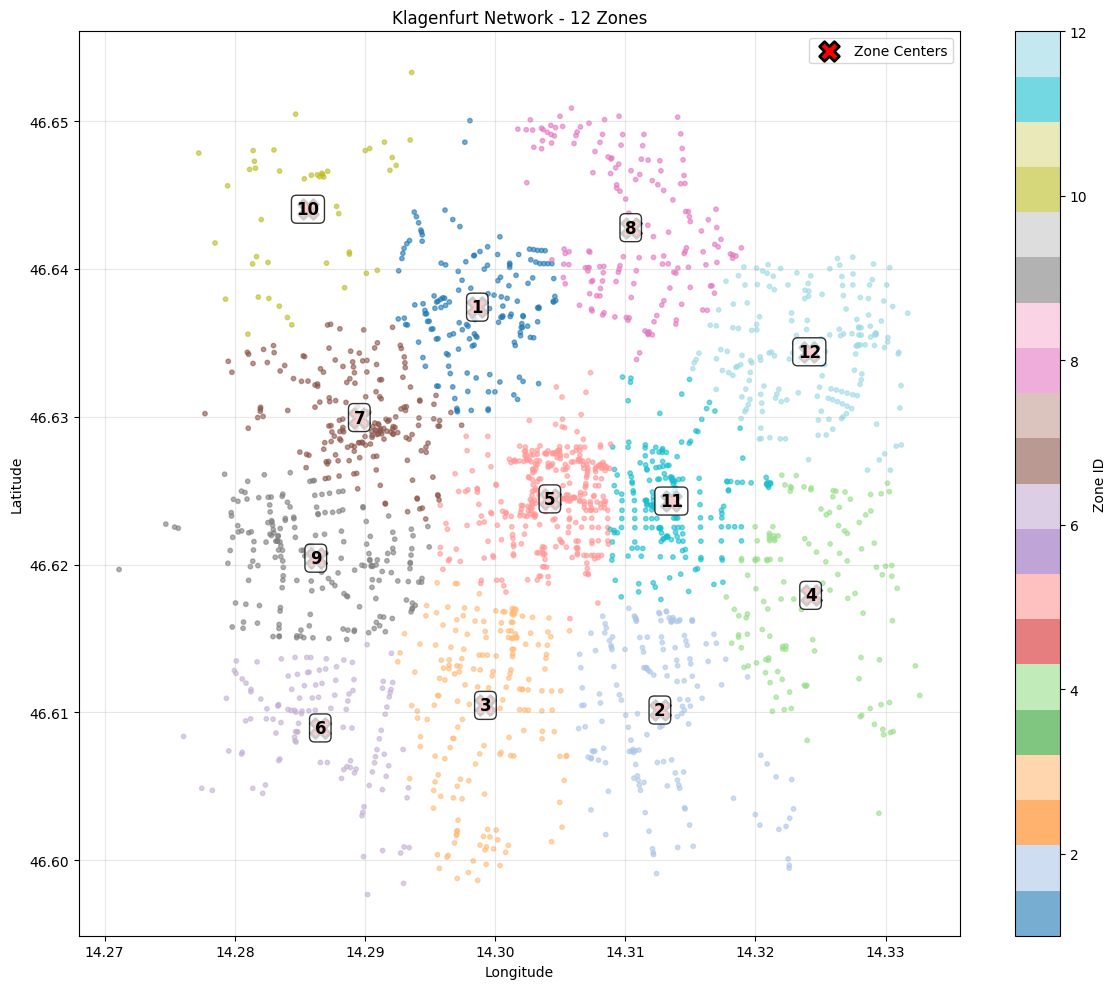

In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import os

# Load nodes
nodes = pd.read_csv('data/networks/klagenfurt/base/nodes.csv')
print(f"Loaded {len(nodes)} nodes")
print(f"Coordinates range:")
print(f"  Longitude: {nodes['pos_x'].min():.6f} to {nodes['pos_x'].max():.6f}")
print(f"  Latitude: {nodes['pos_y'].min():.6f} to {nodes['pos_y'].max():.6f}")

# Munich has ~30k nodes in 108 zones = ~280 nodes per zone
# Klagenfurt has ~2k nodes, so let's aim for similar density
# 2099 / 280 ≈ 7-8 zones, but let's use 12-15 for better granularity
n_zones = 12

# Prepare coordinates for clustering
coords = nodes[['pos_x', 'pos_y']].values

# Use K-means clustering to create zones
print(f"\nCreating {n_zones} zones using K-means clustering...")
kmeans = KMeans(n_clusters=n_zones, random_state=42, n_init=10)
zone_labels = kmeans.fit_predict(coords)

# Add 1 to make zone IDs start from 1 instead of 0
nodes['zone_id'] = zone_labels + 1

# Create zone statistics
zone_stats = nodes.groupby('zone_id').agg({
    'node_index': 'count',
    'pos_x': ['min', 'max', 'mean'],
    'pos_y': ['min', 'max', 'mean']
})
zone_stats.columns = ['node_count', 'lon_min', 'lon_max', 'lon_center', 'lat_min', 'lat_max', 'lat_center']

print(f"\nZone Statistics:")
print(zone_stats)
print(f"\nAverage nodes per zone: {zone_stats['node_count'].mean():.1f}")
print(f"Min/Max nodes per zone: {zone_stats['node_count'].min()} / {zone_stats['node_count'].max()}")

# Visualize the zones
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(nodes['pos_x'], nodes['pos_y'],
                     c=nodes['zone_id'], cmap='tab20',
                     alpha=0.6, s=10)
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
           c='red', marker='X', s=200, edgecolors='black', linewidths=2,
           label='Zone Centers')

# Add zone labels
for i, center in enumerate(kmeans.cluster_centers_):
    ax.text(center[0], center[1], str(i+1),
            fontsize=12, fontweight='bold',
            ha='center', va='center',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.colorbar(scatter, label='Zone ID')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title(f'Klagenfurt Network - {n_zones} Zones')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('klagenfurt_zones_map.png', dpi=150)
print(f"\n✅ Zone map saved to: klagenfurt_zones_map.png")
plt.show()

In [3]:
# Create the node_zone_info.csv file with proper format
# All nodes should be boarding nodes (is_boarding_node=1)
# We'll designate ~10% of nodes in each zone as centroids for better distribution

zone_mapping = pd.DataFrame({
    'node_index': nodes['node_index'],
    'zone_id': nodes['zone_id'],
    'is_centroid': 0,  # Will be set for selected nodes
    'is_boarding_node': 1  # All nodes are boarding nodes
})

# Select centroids: pick nodes closest to zone centers
centroids = []
for zone_id in range(1, n_zones + 1):
    zone_nodes = nodes[nodes['zone_id'] == zone_id]
    center = kmeans.cluster_centers_[zone_id - 1]

    # Calculate distance to center for each node in this zone
    distances = np.sqrt(
        (zone_nodes['pos_x'] - center[0])**2 +
        (zone_nodes['pos_y'] - center[1])**2
    )

    # Select closest 10-20 nodes as centroids
    n_centroids = max(5, len(zone_nodes) // 20)  # At least 5, or ~5% of zone nodes
    closest_nodes = zone_nodes.iloc[distances.argsort()[:n_centroids]]['node_index'].tolist()
    centroids.extend(closest_nodes)

# Mark centroids
zone_mapping.loc[zone_mapping['node_index'].isin(centroids), 'is_centroid'] = 1

print(f"Zone mapping created:")
print(f"  Total nodes: {len(zone_mapping)}")
print(f"  Total zones: {zone_mapping['zone_id'].nunique()}")
print(f"  Total centroids: {zone_mapping['is_centroid'].sum()}")
print(f"  Centroids per zone: {zone_mapping[zone_mapping['is_centroid']==1].groupby('zone_id').size()}")

# Create output directory if it doesn't exist
output_dir = 'data/zones/klagenfurt/base'
os.makedirs(output_dir, exist_ok=True)

# Save the zone mapping
output_file = os.path.join(output_dir, 'node_zone_info.csv')
zone_mapping.to_csv(output_file, index=False)
print(f"\n✅ Zone mapping saved to: {output_file}")

# Display sample
print(f"\nSample zone mapping:")
print(zone_mapping.head(20))

Zone mapping created:
  Total nodes: 2099
  Total zones: 12
  Total centroids: 103
  Centroids per zone: zone_id
1      7
2      8
3      9
4      6
5     17
6      6
7      9
8      8
9      9
10     5
11    10
12     9
dtype: int64

✅ Zone mapping saved to: data/zones/klagenfurt/base/node_zone_info.csv

Sample zone mapping:
    node_index  zone_id  is_centroid  is_boarding_node
0            0        9            0                 1
1            1        9            0                 1
2            2        9            0                 1
3            3        9            0                 1
4            4        9            1                 1
5            5        9            0                 1
6            6        3            0                 1
7            7        3            0                 1
8            8        9            0                 1
9            9        9            1                 1
10          10        9            1                 1
11          